In [139]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

# **`Data Preprocessing:`**



**1.	Preprocess the dataset to handle missing values, remove outliers, and scale the features if necessary.**


In [140]:
file = 'EastWestAirlines.xlsx'
xls = pd.ExcelFile(file)
print(xls.sheet_names)

['Description', 'data']


In [141]:
df = pd.read_excel(file, sheet_name=1)

In [142]:
df.shape

(3999, 12)

In [143]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   ID#                3999 non-null   int64
 1   Balance            3999 non-null   int64
 2   Qual_miles         3999 non-null   int64
 3   cc1_miles          3999 non-null   int64
 4   cc2_miles          3999 non-null   int64
 5   cc3_miles          3999 non-null   int64
 6   Bonus_miles        3999 non-null   int64
 7   Bonus_trans        3999 non-null   int64
 8   Flight_miles_12mo  3999 non-null   int64
 9   Flight_trans_12    3999 non-null   int64
 10  Days_since_enroll  3999 non-null   int64
 11  Award?             3999 non-null   int64
dtypes: int64(12)
memory usage: 375.0 KB


In [144]:
df.head()

,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


In [145]:
#misssing values
df.isnull().sum()

,0
ID#,0
Balance,0
Qual_miles,0
cc1_miles,0
cc2_miles,0
cc3_miles,0
Bonus_miles,0
Bonus_trans,0
Flight_miles_12mo,0
Flight_trans_12,0


In [146]:
#duplicates
df.duplicated().sum()

np.int64(0)

In [147]:
features = df.drop(columns = ['ID#'])
features.head()

,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,28143,0,1,1,1,174,1,0,0,7000,0
1,19244,0,1,1,1,215,2,0,0,6968,0
2,41354,0,1,1,1,4123,4,0,0,7034,0
3,14776,0,1,1,1,500,1,0,0,6952,0
4,97752,0,4,1,1,43300,26,2077,4,6935,1


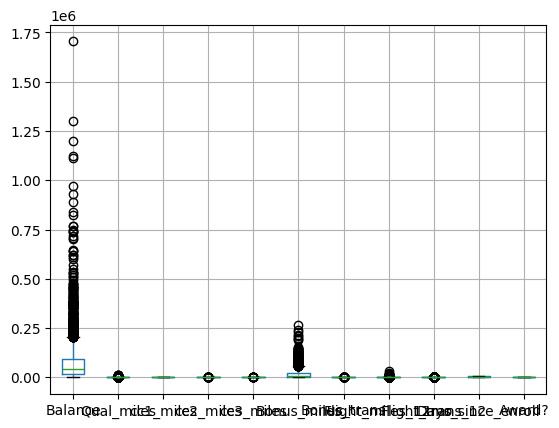

In [148]:
#checking outliers
features.boxplot()
plt.show()

In [149]:
#outlier capping
def outlier_capping(features, column):
  Q1 = features[column].quantile(0.25)
  Q3 = features[column].quantile(0.75)
  IQR = Q3 - Q1
  lower_extreme = Q1 - 1.5*IQR
  upper_extreme = Q3 + 1.5*IQR
  features[column] = features[column].apply(lambda x: lower_extreme if x<lower_extreme else upper_extreme if x>upper_extreme else x)
for col in features.select_dtypes(['int']).columns:
  outlier_capping(features, col)

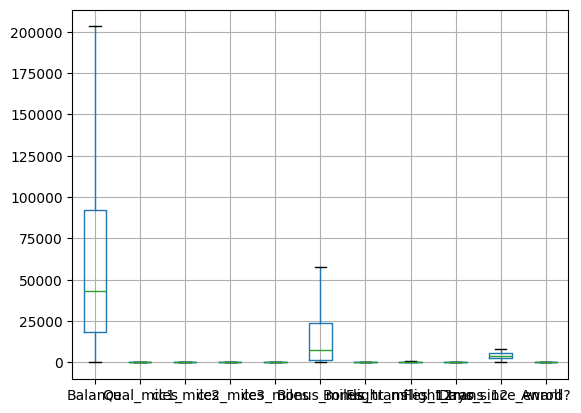

In [150]:
features.boxplot()
plt.show()

In [151]:
#scaling
std_sca = StandardScaler()
features = pd.DataFrame(std_sca.fit_transform(features), columns=features.columns)
features.head()

,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,-0.607258,0.0,-0.769578,0.0,0.0,-0.843091,-1.148854,-0.604313,-0.626143,1.395454,-0.766919
1,-0.758947,0.0,-0.769578,0.0,0.0,-0.840822,-1.039133,-0.604313,-0.626143,1.379957,-0.766919
2,-0.382070,0.0,-0.769578,0.0,0.0,-0.624581,-0.819689,-0.604313,-0.626143,1.411920,-0.766919
3,-0.835106,0.0,-0.769578,0.0,0.0,-0.825052,-1.148854,-0.604313,-0.626143,1.372208,-0.766919
4,0.579265,0.0,1.409471,0.0,0.0,1.543191,1.594189,2.034489,2.020176,1.363975,1.303918


**2.	Perform exploratory data analysis (EDA) to gain insights into the distribution of data and identify potential clusters.**


In [152]:
df.describe()

,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
count,3999.000000,3.999000e+03,3999.000000,3999.000000,3999.000000,3999.000000,3999.000000,3999.00000,3999.000000,3999.000000,3999.00000,3999.000000
mean,2014.819455,7.360133e+04,144.114529,2.059515,1.014504,1.012253,17144.846212,11.60190,460.055764,1.373593,4118.55939,0.370343
std,1160.764358,1.007757e+05,773.663804,1.376919,0.147650,0.195241,24150.967826,9.60381,1400.209171,3.793172,2065.13454,0.482957
min,1.000000,0.000000e+00,0.000000,1.000000,1.000000,1.000000,0.000000,0.00000,0.000000,0.000000,2.00000,0.000000
25%,1010.500000,1.852750e+04,0.000000,1.000000,1.000000,1.000000,1250.000000,3.00000,0.000000,0.000000,2330.00000,0.000000
50%,2016.000000,4.309700e+04,0.000000,1.000000,1.000000,1.000000,7171.000000,12.00000,0.000000,0.000000,4096.00000,0.000000
75%,3020.500000,9.240400e+04,0.000000,3.000000,1.000000,1.000000,23800.500000,17.00000,311.000000,1.000000,5790.50000,1.000000
max,4021.000000,1.704838e+06,11148.000000,5.000000,3.000000,5.000000,263685.000000,86.00000,30817.000000,53.000000,8296.00000,1.000000


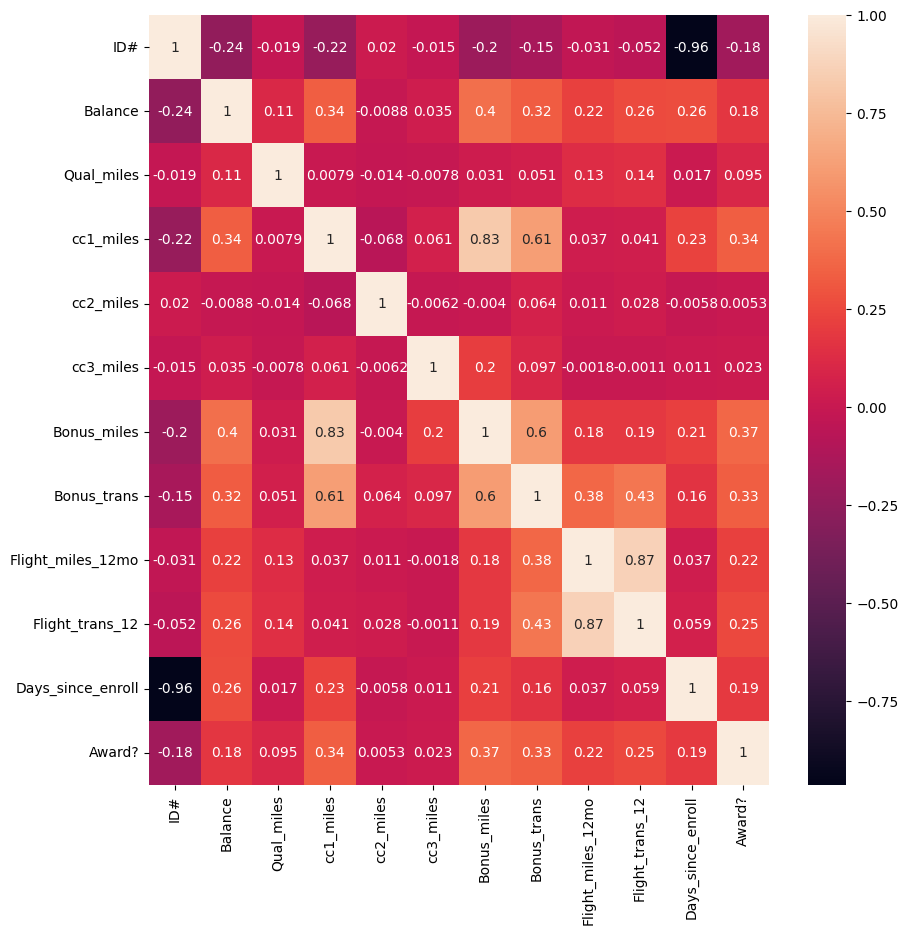

In [153]:
#correlation between features
plt.figure(figsize=(10,10))
sns.heatmap(df.corr(), annot=True)
plt.show()

**3.	Use multiple visualizations to understand the hidden patterns in the dataset**


Histogram:
---

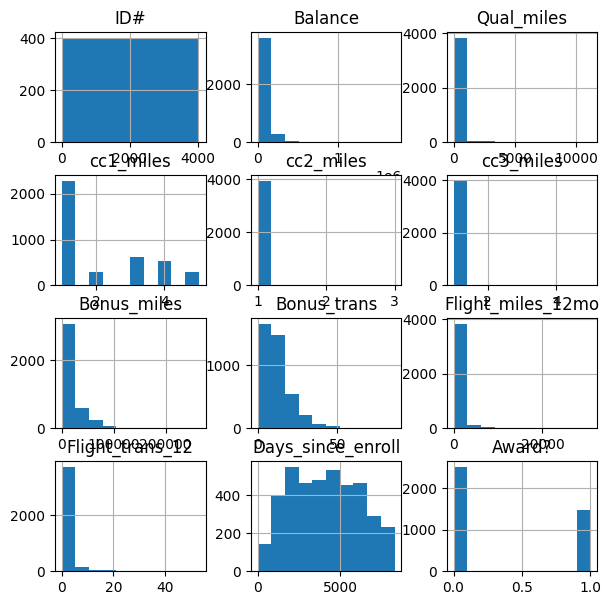

In [154]:
df.hist(figsize=(7,7))
plt.show()

Boxplot:
---

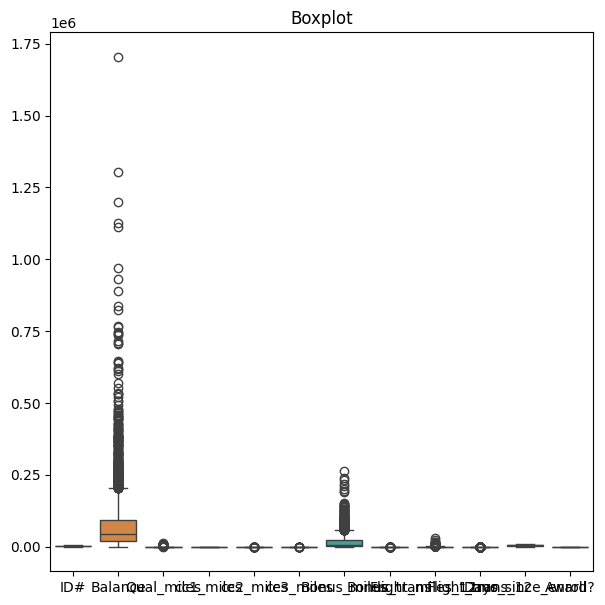

In [155]:
plt.figure(figsize=(7,7))
sns.boxplot(data=df)
plt.title('Boxplot')
plt.show()

Scatter plot:
---

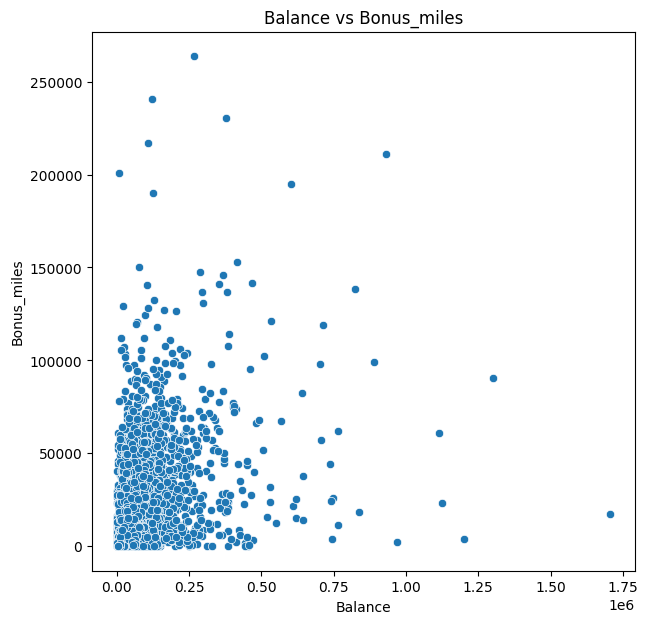

In [156]:
#between Balance and Bonus_miles

plt.figure(figsize=(7,7))
sns.scatterplot(x='Balance', y='Bonus_miles', data=df)
plt.title('Balance vs Bonus_miles')
plt.show()

Pair Plot:
---

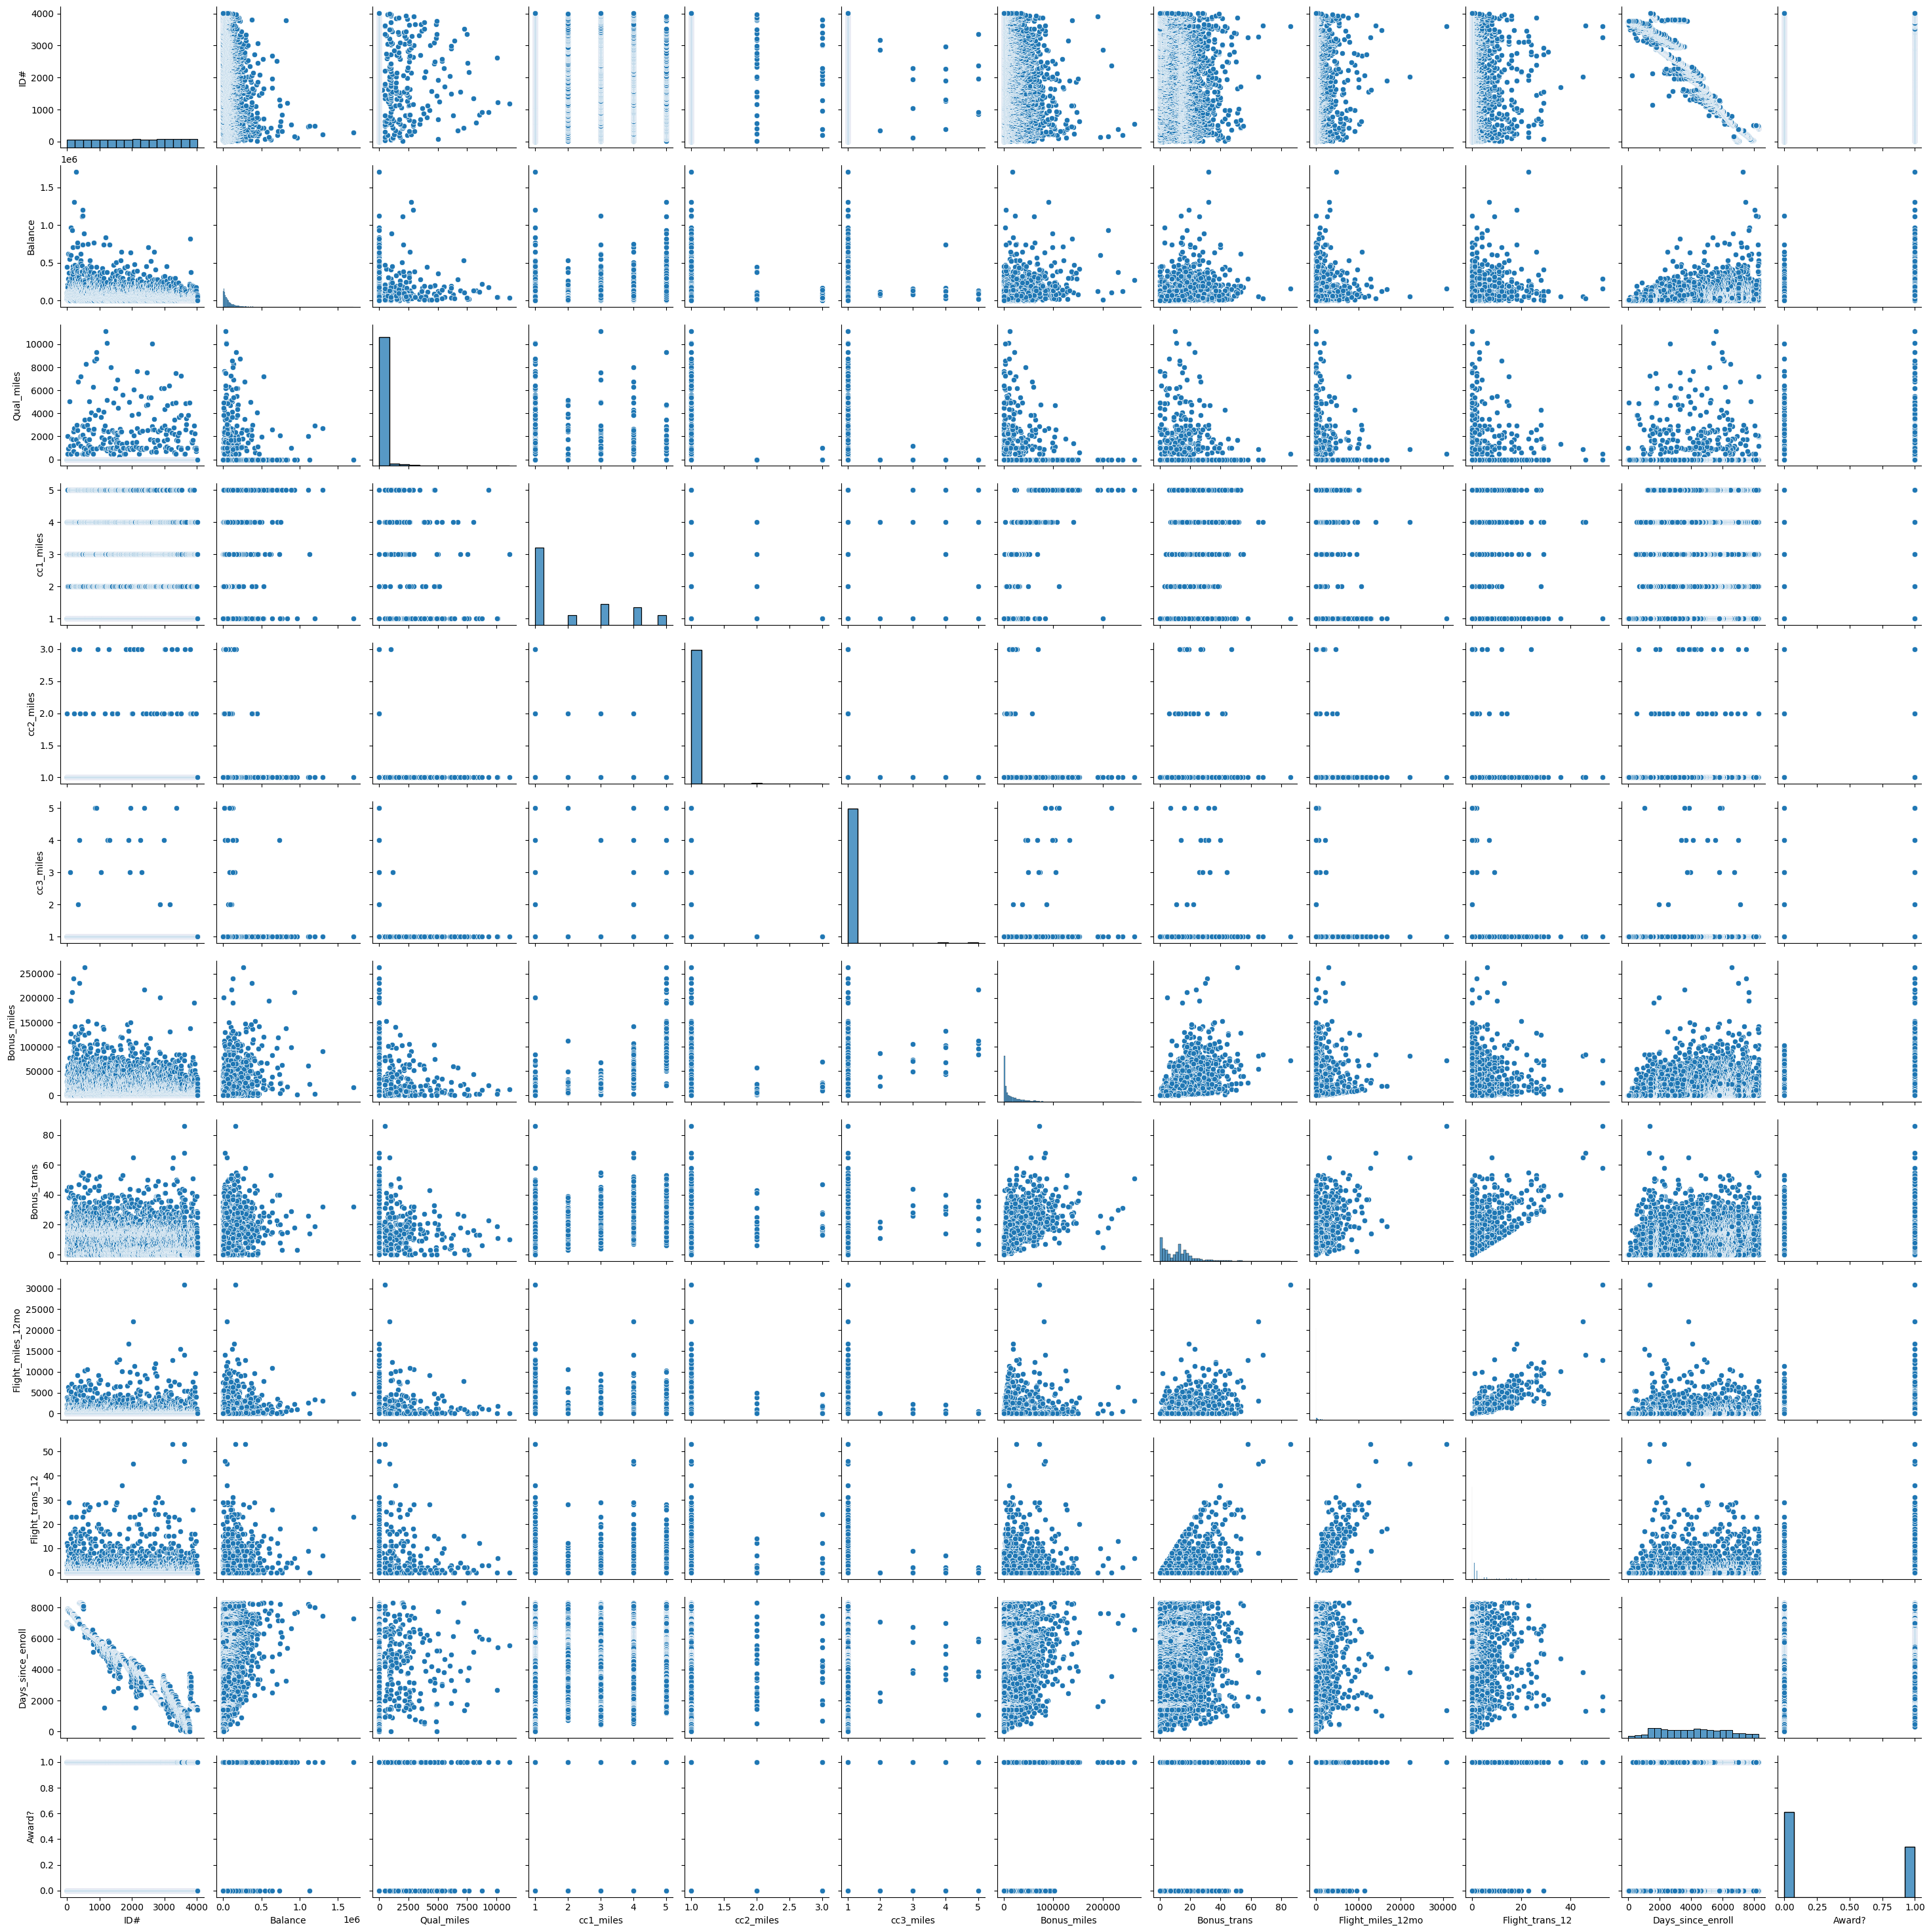

In [157]:
sns.pairplot(df)
plt.show()

Explanation:
---

In Data Preprocessing, I first checked the dataset structure, then verified there are no missing values and no duplicate rows, so the data is clean. After that, I dropped the ID# column because it is only an identification number and does not help in forming clusters. Next, I performed EDA to understand the data distribution by using plots like histograms/boxplots, which helped me identify patterns and extreme values (outliers) in only features. Then I handled the outliers using the IQR capping method so that extreme values won’t disturb clustering. Finally, I used multiple visualizations (like boxplots/correlation heatmap/pair plots) to understand relationships between features.






# **`Implementing Clustering Algorithms:`**


**•	Implement the K-Means and DBSCAN algorithms using a programming language such as Python with libraries like scikit-learn.**


K-Means
---

In [158]:
kmeans = KMeans(n_clusters=3)
cluster = kmeans.fit(features)

In [159]:
cluster.labels_

array([0, 0, 0, ..., 0, 0, 0], dtype=int32)

In [160]:
np.unique(cluster.labels_)

array([0, 1, 2], dtype=int32)

DBSCAN
---

In [161]:
features.head()

,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,-0.607258,0.0,-0.769578,0.0,0.0,-0.843091,-1.148854,-0.604313,-0.626143,1.395454,-0.766919
1,-0.758947,0.0,-0.769578,0.0,0.0,-0.840822,-1.039133,-0.604313,-0.626143,1.379957,-0.766919
2,-0.382070,0.0,-0.769578,0.0,0.0,-0.624581,-0.819689,-0.604313,-0.626143,1.411920,-0.766919
3,-0.835106,0.0,-0.769578,0.0,0.0,-0.825052,-1.148854,-0.604313,-0.626143,1.372208,-0.766919
4,0.579265,0.0,1.409471,0.0,0.0,1.543191,1.594189,2.034489,2.020176,1.363975,1.303918


In [162]:
nn = NearestNeighbors(n_neighbors=20).fit(features)
nn.kneighbors(features)


(array([[0.        , 0.1271148 , 0.18043443, ..., 0.25099143, 0.25890383,
         0.26000025],
        [0.        , 0.12672654, 0.13471398, ..., 0.25665746, 0.25743229,
         0.26111807],
        [0.        , 0.20942913, 0.23342008, ..., 0.47938288, 0.48016399,
         0.48536092],
        ...,
        [0.        , 0.23356857, 0.33602704, ..., 1.16189808, 1.17303617,
         1.18600854],
        [0.        , 0.36229888, 0.44410451, ..., 1.06117454, 1.07491231,
         1.08267539],
        [0.        , 0.00418102, 0.01159521, ..., 0.13352737, 0.13747215,
         0.14676284]]),
 array([[   0,  378,  337, ...,  294,  367,  538],
        [   1,  363,    3, ...,   98,  294,  543],
        [   2,  338,   13, ...,  542,  655,  523],
        ...,
        [3996, 3877, 3800, ..., 2752, 3931, 3567],
        [3997, 3623, 2763, ..., 3633, 3727, 3464],
        [3998, 3491, 3455, ..., 3372, 3827, 3809]]))

In [163]:
distance, index = nn.kneighbors(features)
distance.shape

(3999, 20)

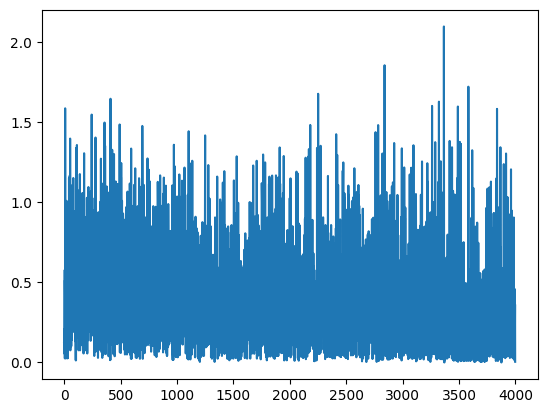

In [164]:
distances = distance[:,1]
plt.plot(distances)
plt.show()

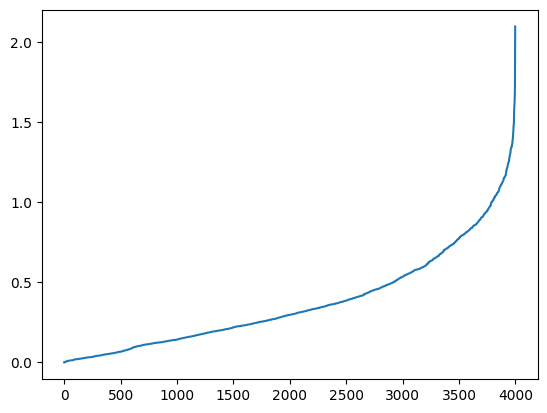

In [165]:
distance = np.sort(distance, axis=0)
dist = distance[:, 1]
plt.plot(dist)
plt.show()

From the above graph eps value is in the range of (0.6 to 0.9) & min_samples =(1, 20)







In [166]:
eps = np.arange(0.6, 0.9, 0.05)
min_nodes = range(5, 21)

In [167]:
output = []
for i in eps:
  for j in min_nodes:
    labels = DBSCAN(eps=i, min_samples=j).fit(features).labels_
    score = silhouette_score(features, labels)
    output.append([i, j, score])
print(output)

[[np.float64(0.6), 5, np.float64(-0.09625039442860876)], [np.float64(0.6), 6, np.float64(-0.12050067267018268)], [np.float64(0.6), 7, np.float64(-0.13643575404460048)], [np.float64(0.6), 8, np.float64(-0.14151885341556492)], [np.float64(0.6), 9, np.float64(-0.10287804414433042)], [np.float64(0.6), 10, np.float64(-0.13144814001226549)], [np.float64(0.6), 11, np.float64(-0.1317802704766794)], [np.float64(0.6), 12, np.float64(-0.14590650909209352)], [np.float64(0.6), 13, np.float64(-0.15931689601507507)], [np.float64(0.6), 14, np.float64(-0.1828677663254621)], [np.float64(0.6), 15, np.float64(-0.16749737361918568)], [np.float64(0.6), 16, np.float64(-0.12546971053107936)], [np.float64(0.6), 17, np.float64(-0.12159589249319169)], [np.float64(0.6), 18, np.float64(-0.11329284532526815)], [np.float64(0.6), 19, np.float64(-0.06287896694092543)], [np.float64(0.6), 20, np.float64(-0.08116196037796393)], [np.float64(0.65), 5, np.float64(-0.11561430271397478)], [np.float64(0.65), 6, np.float64(-0.0

In [168]:
eps, min_nodes, score = sorted(output, key=lambda x:x[2], reverse=True)[0]

In [169]:
print("Best eps:", eps)
print("Best min_samples:", min_nodes)
print("Best Silhouette score:", score)

Best eps: 0.9000000000000002
Best min_samples: 15
Best Silhouette score: 0.016479089917433607


In [170]:
labels = DBSCAN(eps=0.9, min_samples=15).fit(features).labels_

In [171]:
np.unique(labels)

array([-1,  0,  1,  2,  3,  4,  5,  6])

**•	Apply each clustering algorithm to the pre-processed dataset to identify clusters within the data.**


KMeans
---

In [172]:
df['Kmeans_cluster'] = cluster.labels_

In [173]:
df['Kmeans_cluster'].value_counts()

,count
Kmeans_cluster,
0,2254
1,1041
2,704


In [174]:
df.head()

,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?,Kmeans_cluster
0,1,28143,0,1,1,1,174,1,0,0,7000,0,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1,1


DBSCAN:
---

In [175]:
df['DBSCAN_cluster'] = labels

In [176]:
df['DBSCAN_cluster'].value_counts()

,count
DBSCAN_cluster,
0,1801
-1,1214
1,604
3,159
2,99
5,81
4,24
6,17


**•	Experiment with different parameter settings for K-means (Elbow curve for different K values) and DBSCAN (e.g., epsilon, minPts) and evaluate the clustering results.**


In [177]:
inertia = []
for i in range(1, 11):
  kmeans = KMeans(n_clusters = i)
  kmeans.fit(features)
  inertia.append(kmeans.inertia_)
print(inertia)

[31991.999999999996, 22258.774283802188, 17742.35681109319, 16023.40364880725, 13705.049056865619, 12447.032264785483, 11693.0847537037, 11395.750063591046, 10043.613473860587, 9790.891898196536]


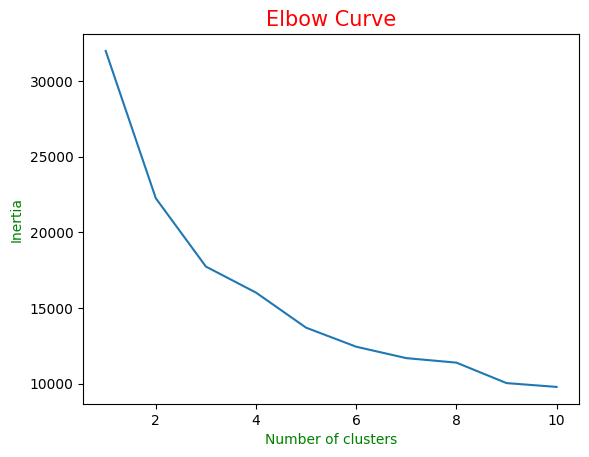

In [178]:
plt.plot(range(1, 11), inertia)
plt.title('Elbow Curve', color = 'red', size=15)
plt.xlabel('Number of clusters', color='green',size=10)
plt.ylabel('Inertia', color='green', size=10)
plt.show()

Explanation:
---

I implemented two clustering algorithms K-Means and DBSCAN. First, K-Means was applied by selecting a fixed number of clusters and the generated cluster labels were stored to identify which data points belong to which cluster. Next, DBSCAN was applied by choosing parameters like eps and min_samples, and it formed clusters. After applying both algorithms, the cluster labels were added back to the original dataframe to clearly identify clusters within the data. For parameter tuning, we used the Elbow Method in K-Means to find the best value of K by checking inertia changes, and for DBSCAN we experimented with multiple eps and min_samples values and selected the best combination using silhouette score. In DBSCAN results, label -1 represents outliers, meaning those records do not belong to any cluster. This comparison helped in understanding how both algorithms group similar customers in different ways based on distance.


# **`Cluster Analysis and Interpretation:`**


**•	Analyse the clusters generated by each clustering algorithm and interpret the characteristics of each cluster. Write you insights in few comments.**




K-Means
---

In [179]:
df['Kmeans_cluster'].value_counts()

,count
Kmeans_cluster,
0,2254
1,1041
2,704


In [180]:
kmeans_summary = df.groupby('Kmeans_cluster').mean()
kmeans_summary

,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?,DBSCAN_cluster
Kmeans_cluster,,,,,,,,,,,,,
0,2240.847826,38761.848270,84.447649,1.334960,1.017746,1.003549,5243.575865,7.210293,18.937445,0.085182,3688.236025,0.181012,0.255546
1,1544.514890,130327.028818,140.852065,3.994236,1.001921,1.037464,46581.034582,20.078770,473.928915,1.445725,4987.302594,0.646494,-0.225744
2,1986.579545,101267.139205,339.974432,1.518466,1.022727,1.002841,11722.106534,13.127841,1851.872159,5.392045,4211.723011,0.568182,0.464489


DBSCAN
---

In [181]:
df['DBSCAN_cluster'].value_counts()

,count
DBSCAN_cluster,
0,1801
-1,1214
1,604
3,159
2,99
5,81
4,24
6,17


In [182]:
outliers = df[df['DBSCAN_cluster'] == -1]
clusters = df[df['DBSCAN_cluster'] != -1]

In [183]:
print("Outliers Count:", outliers.shape[0])
print("clusters Count:", clusters.shape[0])

Outliers Count: 1214
clusters Count: 2785


In [184]:
dbscan_summary = clusters.groupby('DBSCAN_cluster').mean()
dbscan_summary

,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?,Kmeans_cluster
DBSCAN_cluster,,,,,,,,,,,,,
0,2245.192115,40190.888395,55.164353,1.530816,1.012215,1.000555,7029.253748,7.546918,0.000000,0.000000,3674.549139,0.0,0.089395
1,1832.644040,42695.213576,95.945364,2.534768,1.011589,1.006623,20661.254967,11.784768,0.000000,0.000000,4465.357616,1.0,0.435430
2,2109.272727,43640.929293,329.555556,1.030303,1.020202,1.000000,6267.393939,8.969697,1802.717172,5.252525,4026.232323,1.0,2.000000
3,2551.201258,51102.805031,241.188679,1.006289,1.000000,1.000000,3048.566038,6.264151,1614.584906,4.540881,3140.899371,0.0,1.874214
4,1480.250000,309099.083333,1042.500000,1.000000,1.000000,1.000000,13686.375000,12.125000,3052.166667,7.500000,5155.416667,1.0,2.000000
5,2481.222222,33094.987654,134.543210,1.000000,1.000000,1.000000,1795.839506,3.506173,316.888889,1.000000,3317.024691,0.0,0.074074
6,2100.411765,211155.588235,58.823529,4.000000,1.000000,1.000000,40762.294118,18.000000,0.000000,0.000000,3963.470588,0.0,1.000000


Insights:
---
K-Means grouped the customers into 3 clusters based on similar feature patterns and each cluster shows different average behaviour.

DBSCAN formed density-based clusters and also detected noise points where label -1 indicates outliers, so it helps to identify unusual customers.


# **`Visualization:`**


**Visualize the clustering results using scatter plots or other suitable visualization techniques.**


K-Means:
---

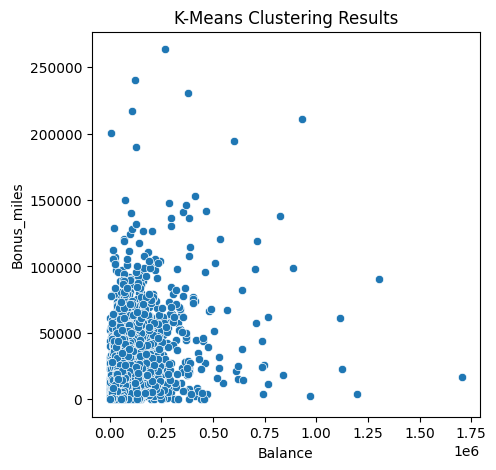

In [185]:
plt.figure(figsize=(5,5))
sns.scatterplot(data=df, x='Balance', y='Bonus_miles')
plt.title('K-Means Clustering Results')
plt.show()

DBSCAN:
---

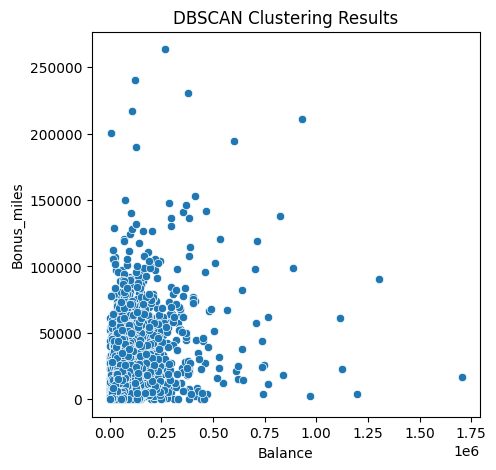

In [186]:
plt.figure(figsize=(5,5))
sns.scatterplot(data=df, x='Balance', y='Bonus_miles')
plt.title('DBSCAN Clustering Results')
plt.show()

**Plot the clusters with different colours to visualize the separation of data points belonging to different clusters.**


K-Means:
---

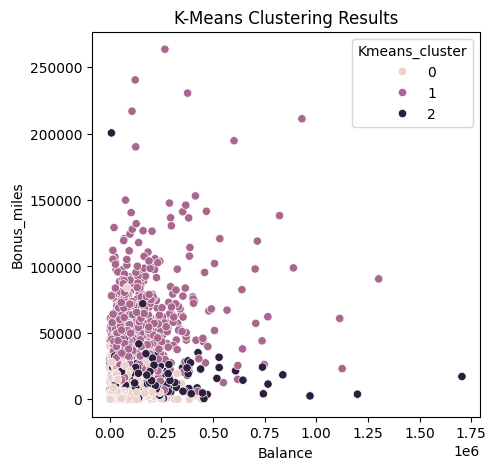

In [187]:
plt.figure(figsize=(5,5))
sns.scatterplot(data=df, x='Balance', y='Bonus_miles', hue='Kmeans_cluster')
plt.title('K-Means Clustering Results')
plt.show()

DBSCAN:
---

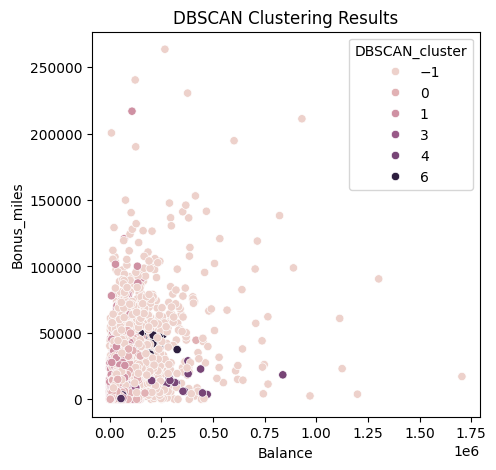

In [188]:
plt.figure(figsize=(5,5))
sns.scatterplot(data=df, x='Balance', y='Bonus_miles', hue='DBSCAN_cluster')
plt.title('DBSCAN Clustering Results')
plt.show()

Explanation:
---

In the visualization, I plotted scatter plots to observe the clustering output from both K-Means and DBSCAN algorithms. I used Balance and Bonus_miles as two important features and displayed the clusters without and also with different colors using the hue parameter. This helps us visually understand how the data points are grouped into different clusters. In DBSCAN, the label -1 represents outliers, meaning those points do not belong to any cluster. Overall, these plots give a clear view of cluster separation and grouping patterns in the dataset.

# **`Evaluation and Performance Metrics:`**


**Evaluate the quality of clustering using internal evaluation metrics such as silhouette score for K-Means and DBSCAN.**

K-Means:
---

In [189]:
kmeans_score = silhouette_score(features, df['Kmeans_cluster'])
print("K-Means Silhouette Score:", kmeans_score)

K-Means Silhouette Score: 0.32931591228742907


DBSCAN:
---

In [190]:
dbscan_clusters = df[df['DBSCAN_cluster'] != -1]
dbscan_score = silhouette_score(features[df['DBSCAN_cluster'] != -1], dbscan_clusters['DBSCAN_cluster'])

In [191]:
print('DBSCAN Silhouette Score(without outliers):', dbscan_score)

DBSCAN Silhouette Score(without outliers): 0.14605486949924668


Explanation:
---

To evaluate clustering quality, we used the Silhouette Score, which measures how well each data point fits within its cluster compared to other clusters. A higher score indicates better cluster separation. We calculated the silhouette score for K-Means. For DBSCAN, we excluded the points labeled -1 because they represent outliers, and then calculated the silhouette score for the remaining clustered points


 K-Means achieved a higher silhouette score (0.3) than DBSCAN (0.1), which means K-Means formed comparatively better separated and more compact clusters for this dataset, while DBSCAN produced weaker cluster separation even after removing outliers(-1).